# 5 · Discover: market segments of the Play Store

**Syllabus:** Module 4 (clustering, similarity and distance, k-means, agglomerative
clustering).

Categories are Google's labels. Do the markets themselves fall into natural groups,
by how big, crowded, loved and paid they are? Each **genre** (the finer label, 47 with
at least 20 apps) is described by six numbers, and genres are grouped without being
told any answer.

| Feature | Measures |
|---|---|
| log10(apps) | competition |
| success rate (share with 1M+ installs) | demand |
| log10(median installs) | demand for a typical app |
| mean rating | how satisfied users already are |
| paid share | willingness to pay |
| top-10 install share | winner-takes-all: how much the 10 biggest apps hold |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram
import common as C
import engine as E

C.style()
apps = C.load_apps()
g = E.genre_table(apps).set_index("genre")
g["top10_share"] = apps.groupby("genre")["installs"].apply(lambda s: s.nlargest(10).sum() / s.sum()).reindex(g.index)
g["log_apps"] = np.log10(g["apps"])
g["log_median_installs"] = np.log10(g["median_installs"])
FEATS = ["log_apps", "success_rate", "log_median_installs", "mean_rating", "paid_share", "top10_share"]
Z = StandardScaler().fit_transform(g[FEATS])
print(len(g), "genres")
g[FEATS].describe().round(2)

47 genres


,log_apps,success_rate,log_median_installs,mean_rating,paid_share,top10_share
count,47.00,47.00,47.00,47.00,47.00,47.00
mean,2.16,0.37,4.99,4.19,0.07,0.69
std,0.38,0.16,0.86,0.10,0.07,0.18
min,1.34,0.05,3.00,3.98,0.00,0.40
25%,1.88,0.24,4.70,4.12,0.02,0.53
50%,2.22,0.39,5.00,4.18,0.05,0.72
75%,2.48,0.47,5.70,4.27,0.10,0.85
max,2.92,0.69,6.00,4.44,0.28,0.99


## 5.1 Distance, and how many groups

Each feature is standardised (mean 0, standard deviation 1) so that no feature wins
just by having bigger numbers; distance is then Euclidean. **k-means** places k
centres and moves them until every genre sits with its nearest centre. The number of
groups k is chosen by the **silhouette**: for each genre, how much closer it is to its
own group than to the next one (from −1 to 1, higher is better). The elbow of the
within-group distance (inertia) is shown alongside.

silhouette: {2: 0.193, 3: 0.239, 4: 0.228, 5: 0.216, 6: 0.226, 7: 0.246, 8: 0.261, 9: 0.25, 10: 0.26}


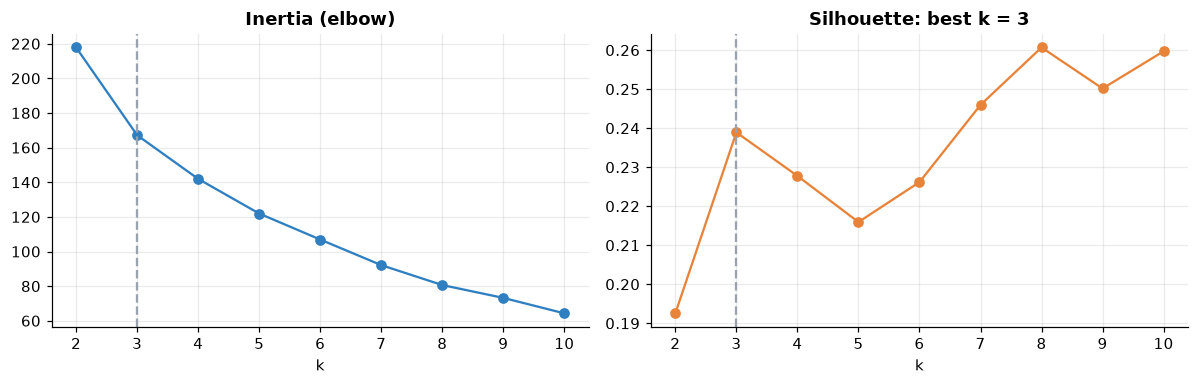

In [2]:
ks = range(2, 11)
inertia, sil = {}, {}
for k in ks:
    km = KMeans(k, n_init=50, random_state=C.SEED).fit(Z)
    inertia[k], sil[k] = km.inertia_, silhouette_score(Z, km.labels_)
best_k = max((k for k in sil if k <= 6), key=sil.get)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(list(ks), list(inertia.values()), marker="o", color=C.PALETTE["main"]); axes[0].set_title("Inertia (elbow)")
axes[1].plot(list(ks), list(sil.values()), marker="o", color=C.PALETTE["accent"]); axes[1].set_title(f"Silhouette: best k = {best_k}")
for ax in axes:
    ax.set_xlabel("k"); ax.axvline(best_k, ls="--", color=C.PALETTE["muted"])
fig.tight_layout(); C.save(fig, "cluster_choose_k")
C.record("cluster.silhouette", sil); C.record("cluster.k", best_k)
print("silhouette:", {k: round(v, 3) for k, v in sil.items()})

**Reading the silhouette.** Every value is below 0.3: the genres do not fall into
sharply separated groups, and that is a finding in itself. Markets shade into one
another. The silhouette keeps creeping up as k grows, because with only 47 genres,
small groups fit tightly. A segment is useful to a founder only if there are few of
them, so k is capped at 6 and the best silhouette within 2-6 is used.

## 5.2 k-means against agglomerative clustering

**Agglomerative clustering** works bottom-up: every genre starts alone, and the two
closest groups are merged again and again (Ward linkage: merge the pair that adds
least within-group variance). The dendrogram shows every merge; cutting it at k groups
gives a second answer. The **adjusted Rand index** measures how much the two answers
agree (1 identical, 0 no better than chance).

adjusted Rand index, k-means vs agglomerative: 0.69


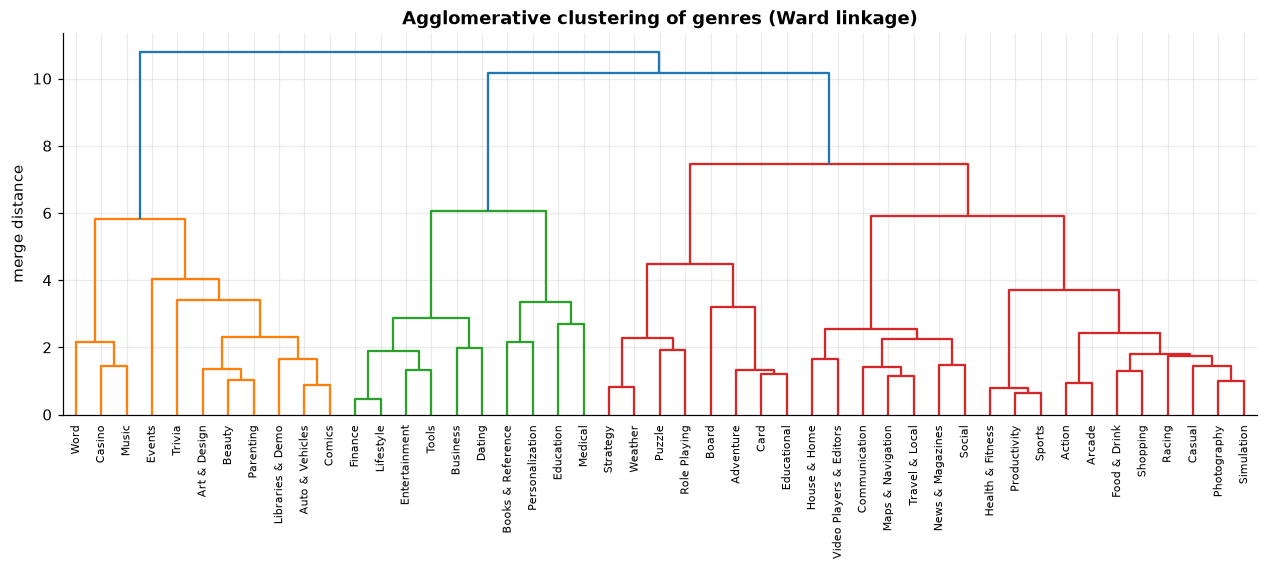

In [3]:
km = KMeans(best_k, n_init=50, random_state=C.SEED).fit(Z)
ag = AgglomerativeClustering(best_k, linkage="ward").fit(Z)
ari = adjusted_rand_score(km.labels_, ag.labels_)
print(f"adjusted Rand index, k-means vs agglomerative: {ari:.2f}")
C.record("cluster.ari_kmeans_agglomerative", ari)
C.record("cluster.silhouette_agglomerative", silhouette_score(Z, ag.labels_))

fig, ax = plt.subplots(figsize=(14, 4.5))
dendrogram(linkage(Z, "ward"), labels=g.index.tolist(), leaf_rotation=90, leaf_font_size=7, ax=ax, color_threshold=None)
ax.set_title("Agglomerative clustering of genres (Ward linkage)"); ax.set_ylabel("merge distance")
C.save(fig, "cluster_dendrogram")

## 5.3 Naming the segments

Each k-means group is named from its centre: demand (success rate) and competition
(number of apps), each called high or low when the centre is more than half a standard
deviation from the average genre, and mixed or mid-sized otherwise. Where two groups
share a name, the feature that separates them most is added.

In [4]:
g["cluster"] = km.labels_
centres = pd.DataFrame(km.cluster_centers_, columns=FEATS)


def name(row, all_rows):
    level = lambda z, hi, lo, mid: hi if z > 0.5 else lo if z < -0.5 else mid
    return level(row["success_rate"], "high demand", "low demand", "mixed demand") + ", " +         level(row["log_apps"], "crowded", "uncrowded", "mid-sized")


names = centres.apply(name, axis=1, all_rows=centres)
for n in names[names.duplicated(keep=False)].unique():
    same = names.index[names == n]
    rest = [f for f in FEATS if f not in ("success_rate", "log_apps")]
    spread = centres.loc[same, rest].std().idxmax()
    for i in same:
        names[i] = f"{n}, {'higher' if centres.loc[i, spread] > centres.loc[same, spread].mean() else 'lower'} {spread.replace('_', ' ')}"
g["segment"] = g["cluster"].map(names)
prof = g.groupby("segment")[["apps", "success_rate", "median_installs", "mean_rating", "paid_share", "top10_share"]].mean()
prof["genres"] = g.groupby("segment").size()
print(prof.round(3))
for seg, members in g.groupby("segment").groups.items():
    print(f"{seg}: {', '.join(members)}")
C.record("cluster.profiles", prof.round(4).to_dict(orient="index"))
C.record("cluster.members", {seg: list(m) for seg, m in g.groupby("segment").groups.items()})
C.record("cluster.genre_segment", g["segment"].to_dict())

                           apps  success_rate  median_installs  mean_rating  \
segment                                                                       
high demand, mid-sized  196.500         0.492       572727.273        4.185   
low demand, crowded     453.000         0.223        16888.889        4.135   
low demand, uncrowded    78.625         0.294       162875.000        4.238   

                        paid_share  top10_share  genres  
segment                                                  
high demand, mid-sized       0.073        0.622      22  
low demand, crowded          0.088        0.539       9  
low demand, uncrowded        0.065        0.874      16  
high demand, mid-sized: Action, Arcade, Casual, Communication, Educational, Food & Drink, Health & Fitness, House & Home, Maps & Navigation, Photography, Productivity, Puzzle, Racing, Role Playing, Shopping, Simulation, Social, Sports, Strategy, Travel & Local, Video Players & Editors, Weather
low demand, crowded

## 5.4 The opportunity map

Competition against demand, every genre placed, coloured by segment. At first sight
the top-left looks like where an idea wants to be: many apps succeed, and few
compete. This map is descriptive. Chapter 6 tests whether low competition and low
ratings actually help an app succeed, and finds that they do not. So the engine's
niche suggestions rank genres by demand (success rate) and how close they are to the
idea, and show competition only as context.

top-left corner (fewer apps than the median genre, higher success rate):
                              category  apps  success_rate  mean_rating  \
genre                                                                     
Racing                            GAME   108         0.694        4.175   
Word                              GAME    23         0.652        4.318   
Strategy                        FAMILY    99         0.606        4.227   
Weather                        WEATHER    79         0.532        4.243   
Role Playing                    FAMILY   115         0.530        4.272   
Music                             GAME    22         0.455        4.219   
Puzzle                          FAMILY   142         0.444        4.371   
Food & Drink            FOOD_AND_DRINK   112         0.438        4.171   
Maps & Navigation  MAPS_AND_NAVIGATION   131         0.412        4.036   
Educational                     FAMILY   102         0.412        4.100   
House & Home            HOU

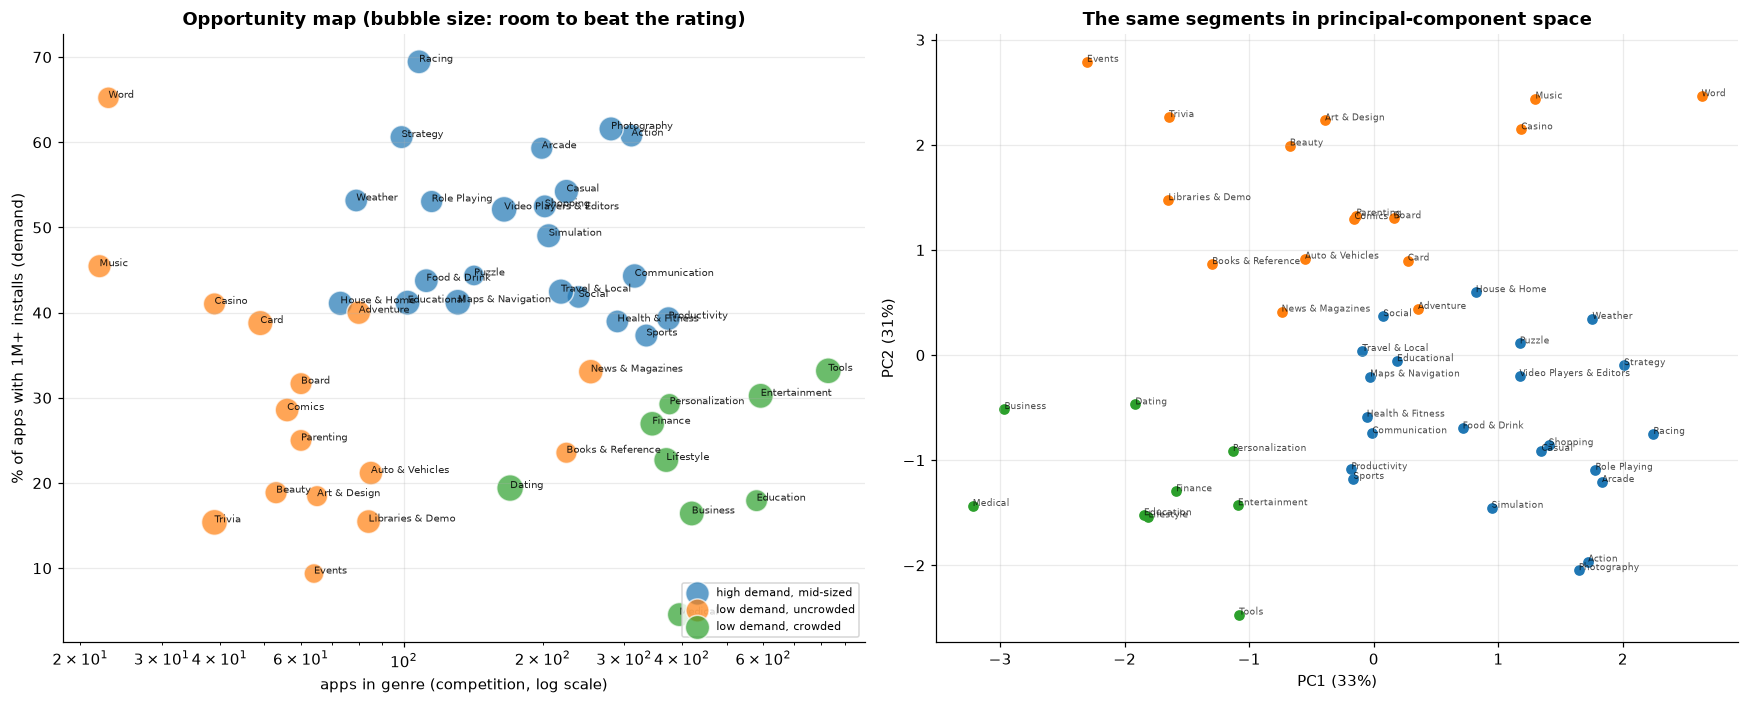

In [5]:
pc = PCA(2).fit(Z)
P = pc.transform(Z)
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
cols = plt.cm.tab10(np.arange(best_k))
for c in range(best_k):
    m = g["cluster"] == c
    axes[0].scatter(g.loc[m, "apps"], g.loc[m, "success_rate"] * 100, s=(5 - g.loc[m, "mean_rating"]) * 300, color=cols[c],
                    alpha=0.7, label=names[c], edgecolor="white")
    axes[1].scatter(P[m.to_numpy(), 0], P[m.to_numpy(), 1], color=cols[c], label=names[c])
for gen, r in g.iterrows():
    axes[0].annotate(gen, (r["apps"], r["success_rate"] * 100), fontsize=6.5, alpha=0.85)
axes[0].set_xscale("log"); axes[0].set_xlabel("apps in genre (competition, log scale)"); axes[0].set_ylabel("% of apps with 1M+ installs (demand)")
axes[0].set_title("Opportunity map (bubble size: room to beat the rating)"); axes[0].legend(fontsize=7, loc="lower right")
for i, gen in enumerate(g.index):
    axes[1].annotate(gen, P[i], fontsize=6, alpha=0.7)
axes[1].set_xlabel(f"PC1 ({pc.explained_variance_ratio_[0]:.0%})"); axes[1].set_ylabel(f"PC2 ({pc.explained_variance_ratio_[1]:.0%})")
axes[1].set_title("The same segments in principal-component space")
fig.tight_layout(); C.save(fig, "cluster_opportunity")
C.record("cluster.pca_explained", pc.explained_variance_ratio_.round(3))
cols = ["category", "apps", "success_rate", "mean_rating", "segment"]
corner = g[(g["apps"] < g["apps"].median()) & (g["success_rate"] > g["success_rate"].median())].sort_values("success_rate", ascending=False)[cols]
print("top-left corner (fewer apps than the median genre, higher success rate):"); print(corner.round(3))
C.record("cluster.top_left", corner.round(3).reset_index().to_dict(orient="records"))
crowded_low = g[(g["apps"] > g["apps"].median()) & (g["success_rate"] < g["success_rate"].median())].sort_values("success_rate")[cols]
C.record("cluster.bottom_right", crowded_low.round(3).reset_index().to_dict(orient="records"))
print("bottom-right corner (crowded, low success):", crowded_low.index.tolist())